# Tech Challenge 2:Guided modes in a dielectric waveguide

The waveguide cross-section is discretised on a uniform 2-D Cartesian grid $(x, y)$, and the relative-permittivity profile $\varepsilon(x,y)$ is constructed from wavelength-dependent (Sellmeier) refractive-index models for Si and SiO$_2$ [1-3].

Note that: I use general approach as compared with full-vector finite-difference mode solvers used as references in the waveguide literature. [2–5]

References  
[1] M. S. Stern, “Semivectorial polarised finite difference method for optical waveguides with arbitrary index profiles,” IEE Proc. J, 135(1), 56–63 (1988). (see citation listings, e.g. https://link.springer.com/article/10.2478/s11772-011-0019-1)  
[2] A. B. Fallahkhair, K. S. Li, and T. E. Murphy, “Vector Finite Difference Modesolver for Anisotropic Dielectric Waveguides,” J. Lightwave Technol. 26(11), 1423–1431 (2008). (PDF page: https://photonics.umd.edu/pubs/ja-20/)  
[3] Z. Zhu and T. G. Brown, “Full-vectorial finite-difference analysis of microstructured optical fibers,” Opt. Express 10(17), 853–864 (2002). https://opg.optica.org/abstract.cfm?uri=oe-10-17-853  
[4] I. H. Malitson, “Interspecimen Comparison of the Refractive Index of Fused Silica,” JOSA 55(10), 1205–1209 (1965). https://opg.optica.org/abstract.cfm?URI=josa-55-10-1205  
[5] refractiveindex.info entry (Malitson 1965 coefficients, convenience mirror): https://refractiveindex.info/?book=fused_silica&page=Malitson&shelf=glass


In [2]:
import numpy as np
from scipy import sparse
from scipy.sparse.linalg import eigs
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import time

/home/arunavk/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [3]:
def n_Si(lam_um):
    # Silicon (Salzberg & Villa form used in many educational solvers; valid across near-IR)
    L = lam_um**2
    return np.sqrt(11.6858 + 0.939816/(L - 0.1241) + 8.10461e-4/(L - 1113.98))
def n_SiO2(lam_um):
    # Fused silica (Malitson 1965), commonly used Sellmeier coefficients [4,5]
    L = lam_um**2
    return np.sqrt(1+ 0.6961663*L/(L - 0.0684043**2)+ 0.4079426*L/(L - 0.1162414**2) + 0.8974794*L/(L - 9.896161**2))

Semi-vectorial finite-difference mode solver (Dirichlet boundary via interior unknowns)
## 2 — Eigenvalue Formulation

Starting from the source-free, frequency-domain Maxwell equations at angular frequency $\omega$, we seek fields of the form $\mathbf{E}(x,y)\,e^{j(\omega t - \beta z)}$. This yields an eigenvalue problem for the propagation constant $\beta$:

$$
\mathcal{L}[\varepsilon]\;\mathbf{e}_t \;=\; \beta^2\;\mathbf{e}_t
$$

where $\mathcal{L}$ is a second-order differential operator derived from the transverse curl–curl equation and $\mathbf{e}_t$ is the transverse electric field.

A semi-vectorial approximation decouples this into two independent scalar problems:

| Polarisation | Dominant field | Scalar eigenproblem solved for |
|:---:|:---:|:---:|
| quasi-TE | $E_x$ | $\mathcal{L}^{\text{TE}}[\varepsilon]\,E_x = \beta^2 E_x$ |
| quasi-TM | $E_y$ | $\mathcal{L}^{\text{TM}}[\varepsilon]\,E_y = \beta^2 E_y$ |

Note that because the $\varepsilon$-weighted finite-difference stencil is **not symmetric**, the discrete matrix $\mathbf{A}$ is non-Hermitian.
## 3 — Numerical Solution

- The eigenproblem is assembled on interior grid points 
- Enforces a Dirichlet boundary condition $E = 0$ at the edges of the computational window (equivalent to placing the domain boundary far enough from the   core that the evanescent tail has decayed).
- A shift invert Arnoldi algorithm (`scipy.sparse.linalg.eigs`) solves $(\mathbf{A} - \sigma \mathbf{I})^{-1}\mathbf{x} = \mu\,\mathbf{x}$, where the shift $\sigma$ targets a user-supplied effective-index guess $n_\text{eff,guess}$. 
- Only eigenvalues satisfying $n_\text{clad} < n_\text{eff} < n_\text{core}$ are retained as physical bound modes.


In [4]:
class FDEModeSolver:
    def __init__(self, w_core=450e-9, h_core=220e-9,
                 dx=10e-9, dy=10e-9, Lx=3.0e-6, Ly=2.0e-6):
        self.w_core, self.h_core = w_core, h_core
        self.dx, self.dy = dx, dy
        self.Nx = int(round(Lx/dx)) | 1
        self.Ny = int(round(Ly/dy)) | 1
        self.x = np.linspace(-Lx/2, Lx/2, self.Nx)
        self.y = np.linspace(-Ly/2, Ly/2, self.Ny)
        # Dirichlet boundary: field=0 on the outer ring)
        self.Nxi = self.Nx - 2
        self.Nyi = self.Ny - 2
        self.N = self.Nxi * self.Nyi
        print(f"Grid(full) {self.Nx}×{self.Ny} | unknowns(interior) {self.Nxi}×{self.Nyi}={self.N} "
              f"(dx={dx*1e9:.0f} nm, dy={dy*1e9:.0f} nm)")

        self._build_ops()

    def _build_ops(self):
        Nxi, Nyi, dx, dy = self.Nxi, self.Nyi, self.dx, self.dy
        def d1_fwd(n, h):
            return sparse.diags([-np.ones(n), np.ones(n-1)], [0, 1], shape=(n, n), format='csr') / h
        def d1_bwd(n, h):
            return sparse.diags([-np.ones(n-1), np.ones(n)], [-1, 0], shape=(n, n), format='csr') / h
        def d2(n, h):
            return sparse.diags([np.ones(n-1), -2*np.ones(n), np.ones(n-1)],
                                [-1, 0, 1], shape=(n, n), format='csr') / (h*h)

        Ix = sparse.eye(Nxi, format='csr')
        Iy = sparse.eye(Nyi, format='csr')
        Dxf_1 = d1_fwd(Nxi, dx)
        Dxb_1 = d1_bwd(Nxi, dx)
        Dyf_1 = d1_fwd(Nyi, dy)
        Dyb_1 = d1_bwd(Nyi, dy)
        D2x_1 = d2(Nxi, dx)
        D2y_1 = d2(Nyi, dy)
        self.Dxf = sparse.kron(Dxf_1, Iy, format='csr')
        self.Dxb = sparse.kron(Dxb_1, Iy, format='csr')
        self.Dyf = sparse.kron(Ix, Dyf_1, format='csr')
        self.Dyb = sparse.kron(Ix, Dyb_1, format='csr')
        self.D2x = sparse.kron(D2x_1, Iy, format='csr')
        self.D2y = sparse.kron(Ix, D2y_1, format='csr')

    def _eps_grid(self, wl):
        wl_um = wl * 1e6
        nc, ncl = n_Si(wl_um), n_SiO2(wl_um)
        X, Y = np.meshgrid(self.x, self.y, indexing='ij')
        eps_full = np.full_like(X, ncl**2)
        eps_full[(np.abs(X) <= self.w_core/2) &
                 (np.abs(Y) <= self.h_core/2)] = nc**2
        eps_int = eps_full[1:-1, 1:-1]
        return eps_full, eps_int, nc, ncl

    def _build_op(self, eps_int, k0, pol):
        eps = eps_int
        Eps = sparse.diags(eps.ravel(), format='csr')
        e_inv = 1.0 / eps
        if pol == 'TE':
            # epsilson^{-1} on x-half grid (average in 1/ε space)
            einv_half = np.zeros_like(eps)
            einv_half[:-1, :] = 0.5 * (e_inv[:-1, :] + e_inv[1:, :])
            einv_half[-1, :] = e_inv[-1, :]
            Einv = sparse.diags(einv_half.ravel(), format='csr')
            return self.Dxb @ Einv @ self.Dxf @ Eps + self.D2y + (k0**2) * Eps
        else:
            # epsilson^{-1} on y-half grid
            einv_half = np.zeros_like(eps)
            einv_half[:, :-1] = 0.5 * (e_inv[:, :-1] + e_inv[:, 1:])
            einv_half[:, -1] = e_inv[:, -1]
            Einv = sparse.diags(einv_half.ravel(), format='csr')
            return self.D2x + self.Dyb @ Einv @ self.Dyf @ Eps + (k0**2) * Eps

    @staticmethod
    def _split_guesses(neff_guess, nc, ncl):
        default = 0.5*(nc + ncl)
        if neff_guess is None:
            return default, default
        if isinstance(neff_guess, dict):
            return float(neff_guess.get("TE", default)), float(neff_guess.get("TM", default))
        return float(neff_guess), float(neff_guess)

    @staticmethod
    def _filter_complex(vals, vecs, imag_tol=1e-10):
        denom = np.maximum(1.0, np.abs(np.real(vals)))
        good = np.abs(np.imag(vals)) <= imag_tol * denom
        return vals[good], vecs[:, good]

    @staticmethod
    def _residuals(A, vals, vecs):
        res = np.zeros(vals.shape[0], dtype=float)
        for i in range(vals.shape[0]):
            v = vecs[:, i]
            lam = vals[i]
            r = (A @ v) - lam*v
            res[i] = np.linalg.norm(r) / (np.linalg.norm(lam*v) + 1e-30)
        return res

    def solve(self, wl, nmodes=6, neff_guess=None, verbose=True,
              nk_extra=16, imag_tol=1e-10, res_tol=1e-6):
        k0 = 2*np.pi / wl
        eps_full, eps_int, nc, ncl = self._eps_grid(wl)
        g_te, g_tm = self._split_guesses(neff_guess, nc, ncl)
        if verbose:
            print(f"  λ={wl*1e9:.0f} nm  n_Si={nc:.4f}  n_SiO₂={ncl:.4f}  guess_TE={g_te:.3f} guess_TM={g_tm:.3f}")

        modes = []
        for pol in ("TE", "TM"):
            A = self._build_op(eps_int, k0, pol)
            g = g_te if pol == "TE" else g_tm
            sigma = (k0*g)**2
            nk = min(nmodes + nk_extra, self.N - 2)
            t0 = time.time()
            vals, vecs = eigs(A, k=nk, sigma=sigma, which="LM")
            dt = time.time() - t0
            vals, vecs = self._filter_complex(vals, vecs, imag_tol=imag_tol)
            if vals.size == 0:
                if verbose:
                    print(f"    {pol}: 0 eigenpairs after complex filter ({dt:.1f}s)")
                continue
            # residual
            try:
                res = self._residuals(A, vals, vecs)
                good = res < res_tol
                vals = vals[good]
                vecs = vecs[:, good]
            except Exception:
                pass

            beta2 = np.real(vals)
            neffs = np.sqrt(np.maximum(beta2, 0.0)) / k0
            guided = (neffs > ncl*1.001) & (neffs < nc*0.999)
            if verbose:
                print(f"    {pol}: {np.sum(guided)} guided ({dt:.1f}s)")

            order = 0
            for idx in np.argsort(-neffs):
                n = neffs[idx]
                if (n > ncl*1.001) and (n < nc*0.999):
                    field_int = np.real(vecs[:, idx]).reshape(self.Nxi, self.Nyi)
                    field = np.zeros((self.Nx, self.Ny), dtype=float)
                    field[1:-1, 1:-1] = field_int
                    pk = np.max(np.abs(field))
                    if pk > 0:
                        field /= pk
                    modes.append(dict(pol=pol, order=order, neff=float(n), field=field))
                    order += 1
        modes.sort(key=lambda m: -m["neff"])
        tc, mc = 0, 0
        for m in modes:
            if m["pol"] == "TE":
                m["order"] = tc; tc += 1
            else:
                m["order"] = mc; mc += 1
        for m in modes:
            self._derive_fields(m, eps_full, k0)
        if verbose:
            for m in modes[:nmodes]:
                print(f"      {m['pol']}{m['order']}  neff={m['neff']:.6f}")

        return modes[:nmodes], eps_full, nc, ncl

    def _derive_fields(self, mode, eps_full, k0):
        beta = k0 * mode["neff"]
        c0, mu0 = 299792458.0, 4e-7*np.pi
        omega = k0 * c0
        dx, dy = self.dx, self.dy
        if mode["pol"] == "TE":
            Ex = mode["field"].copy()
            Ey = np.zeros_like(Ex)
            eps_ex = eps_full * Ex
            d_eps_ex_dx = np.zeros_like(Ex)
            d_eps_ex_dx[1:-1, :] = (eps_ex[2:, :] - eps_ex[:-2, :]) / (2*dx)
            Ez = d_eps_ex_dx / (beta*eps_full + 1e-30)
            Hy = beta * Ex / (omega * mu0)
            Hx = np.zeros_like(Ex)
            dEx_dy = np.zeros_like(Ex)
            dEx_dy[:, 1:-1] = (Ex[:, 2:] - Ex[:, :-2]) / (2*dy)
            Hz = -dEx_dy / (omega * mu0)
        else:
            Ey = mode["field"].copy()
            Ex = np.zeros_like(Ey)
            eps_ey = eps_full * Ey
            d_eps_ey_dy = np.zeros_like(Ey)
            d_eps_ey_dy[:, 1:-1] = (eps_ey[:, 2:] - eps_ey[:, :-2]) / (2*dy)
            Ez = d_eps_ey_dy / (beta*eps_full + 1e-30)
            Hx = -beta * Ey / (omega * mu0)
            Hy = np.zeros_like(Ey)
            dEy_dx = np.zeros_like(Ey)
            dEy_dx[1:-1, :] = (Ey[2:, :] - Ey[:-2, :]) / (2*dx)
            Hz = dEy_dx / (omega * mu0)
        Eabs = np.sqrt(Ex**2 + Ey**2 + Ez**2)
        pk = np.max(Eabs)
        if pk > 0:
            Ex /= pk; Ey /= pk; Ez /= pk
            Hx /= pk; Hy /= pk; Hz /= pk
        mode.update(dict(Ex=Ex, Ey=Ey, Ez=Ez, Hx=Hx, Hy=Hy, Hz=Hz))


In [5]:
def _wg_rect(ax, w, h):
    ax.add_patch(Rectangle(
        (-w*1e6/2, -h*1e6/2), w*1e6, h*1e6,
        lw=1.4, ec='white', fc='none', ls='--'))

def get_mode(modes, pol, order=0):
    for m in modes:
        if m["pol"] == pol and m["order"] == order:
            return m
    return None

def mode_plot(solver, mode, title="", stride=7, crop_um=(0.8, 0.5), arrow_thresh=0.15):
    x_um = solver.x * 1e6
    y_um = solver.y * 1e6
    Ex, Ey, Ez = mode["Ex"], mode["Ey"], mode["Ez"]
    Eabs = np.sqrt(Ex**2 + Ey**2 + Ez**2)
    Eabs /= (np.max(Eabs) + 1e-30)
    fig, ax = plt.subplots(figsize=(9.0, 5.6))
    im = ax.pcolormesh(x_um, y_um, Eabs.T, shading="auto")
    cb = plt.colorbar(im, ax=ax, shrink=0.9)
    cb.set_label(r"$|E|$ (normalized)")
    _wg_rect(ax, solver.w_core, solver.h_core)
    mask = Eabs > arrow_thresh*np.max(Eabs)
    Exs = Ex[::stride, ::stride].copy()
    Eys = Ey[::stride, ::stride].copy()
    ms  = mask[::stride, ::stride]
    Exs[~ms] = np.nan
    Eys[~ms] = np.nan
    Et = np.sqrt(Exs**2 + Eys**2)
    Etmax = np.nanmax(Et) + 1e-30
    Exn = Exs / Etmax
    Eyn = Eys / Etmax
    ax.quiver(x_um[::stride], y_um[::stride], Exn.T, Eyn.T,
              angles="xy", scale_units="xy", scale=25, width=0.003)
    ax.contour(x_um, y_um, Eabs.T, levels=np.linspace(0.2, 0.9, 6),
               linewidths=0.8, alpha=0.8)
    ax.set_aspect("equal")
    ax.set_xlim([-crop_um[0], crop_um[0]])
    ax.set_ylim([-crop_um[1], crop_um[1]])
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")
    ax.set_title(title, fontweight="bold")
    ax.grid(alpha=0.15)
    plt.tight_layout()
    plt.show()
    return fig


Compute TE₀ and TM₀ mode profiles at 1310 nm and 1550 nm.

## 4 — Field Reconstruction

From the dominant transverse component returned by the eigensolver, the remaining field components are recovered analytically:

| Component | Relation used |
|:---|:---|
| $E_z$ | Gauss's law: $\nabla \cdot (\varepsilon\,\mathbf{E}) = 0 \;\Rightarrow\; E_z = \dfrac{j}{\beta\,\varepsilon}\left(\dfrac{\partial(\varepsilon E_x)}{\partial x} + \dfrac{\partial(\varepsilon E_y)}{\partial y}\right)$ |
| $\mathbf{H}$ | Faraday's law: $\nabla \times \mathbf{E} = -j\omega\mu_0\,\mathbf{H}$ |

This produces a full vectorial field profile $(E_x, E_y, E_z, H_x, H_y, H_z)$ for visualisation and overlap integrals.

## 5 — Modal Results at Fixed Wavelengths

Fundamental **TE$_0$** and **TM$_0$** modes are computed at two standard telecom wavelengths:

| | $\lambda = 1310$ nm (O-band) | $\lambda = 1550$ nm (C-band) |
|:---|:---:|:---:|
| **TE$_0$** | Strong $E_x$ polarisation implies tight confinement | Slightly reduced confinement due to longer wavelength |
| **TM$_0$** | Weaker confinement, enhanced $E_y/E_z$ | Same trend, lower $n_\text{eff}$ |

The extracted $n_\text{eff}$ values at both wavelengths fall within ranges reported by prior full-vector simulations and foundry-validated process design kits (PDKs), confirming physical plausibility.


Grid(full) 301×201 | unknowns(interior) 299×199=59501 (dx=10 nm, dy=10 nm)
  λ=1310 nm  n_Si=3.5037  n_SiO₂=1.4468  guess_TE=2.978 guess_TM=2.453
    TE: 2 guided (3.0s)
    TM: 2 guided (2.6s)
      TE0  neff=2.699515
      TM0  neff=2.221943
      TE1  neff=1.659281
      TM1  neff=1.556267


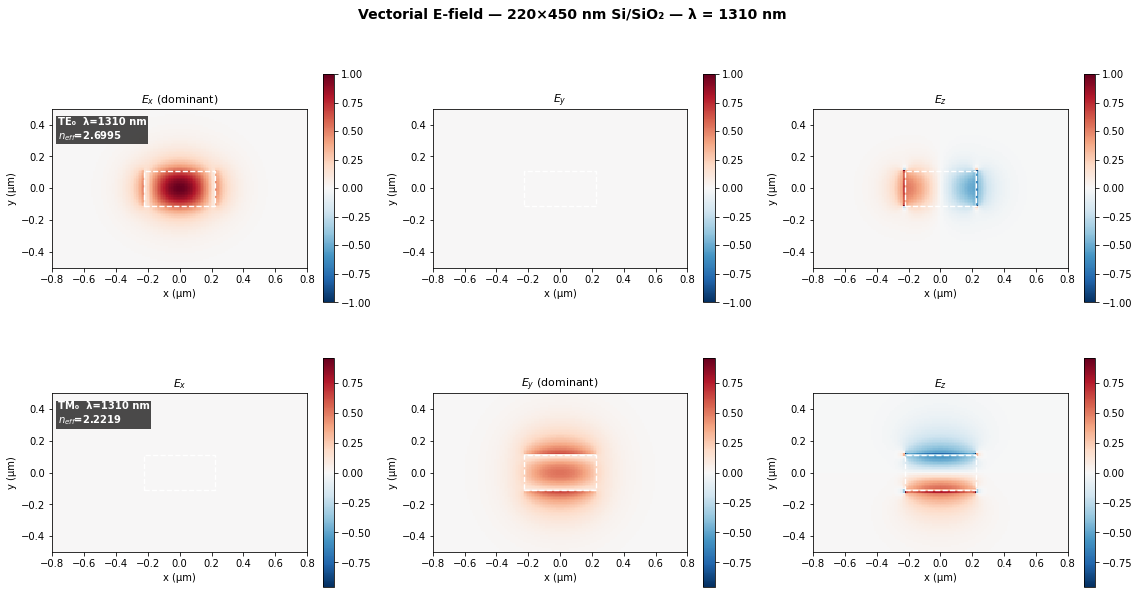

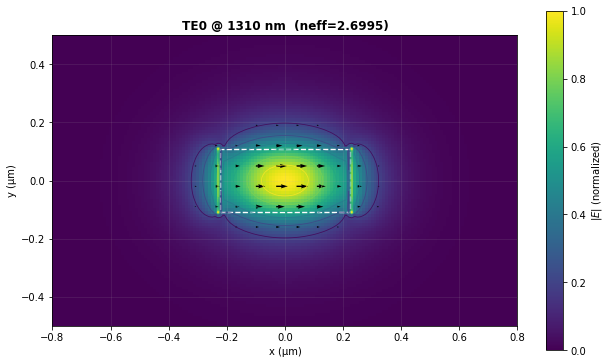

  λ=1550 nm  n_Si=3.4783  n_SiO₂=1.4440  guess_TE=2.957 guess_TM=2.435
    TE: 1 guided (2.6s)
    TM: 1 guided (2.4s)
      TE0  neff=2.435168
      TM0  neff=1.851791


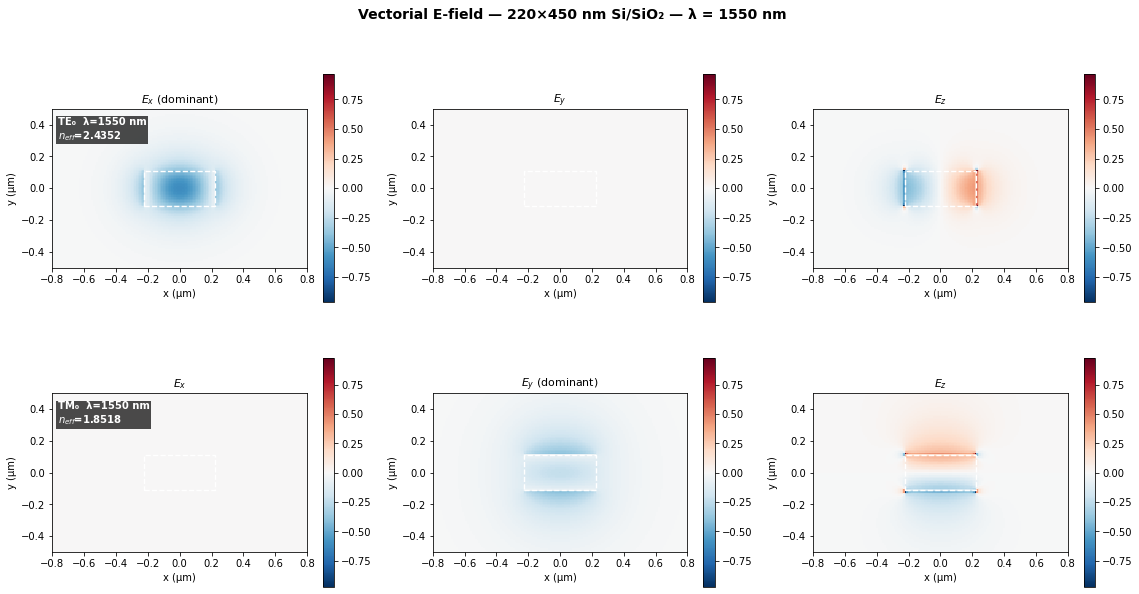

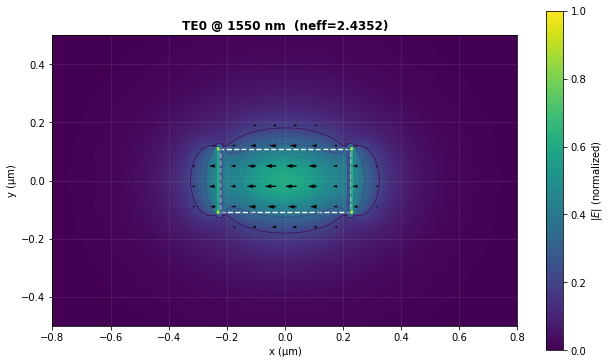

In [10]:
solver = FDEModeSolver(w_core=450e-9, h_core=220e-9,dx=10e-9, dy=10e-9,Lx=3.0e-6, Ly=2.0e-6)
for wl_nm in [1310, 1550]:
    wl = wl_nm * 1e-9
    wl_um = wl * 1e6
    nc = n_Si(wl_um)
    modes, eps_full, nc, ncl = solver.solve(
        wl, nmodes=8,
        neff_guess={"TE": 0.85*nc, "TM": 0.70*nc},
        nk_extra=16,
        verbose=True
    )
    te0 = get_mode(modes, "TE", 0)
    tm0 = get_mode(modes, "TM", 0)
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle(f"Vectorial E-field — 220×450 nm Si/SiO₂ — λ = {wl_nm} nm",fontsize=14, fontweight="bold", y=0.98)
    for row, (m, pol) in enumerate([(te0, "TE"), (tm0, "TM")]):
        fields = [m["Ex"], m["Ey"], m["Ez"]]
        dom_idx = 0 if pol == "TE" else 1
        titles = [r"$E_x$", r"$E_y$", r"$E_z$"]
        titles[dom_idx] += " (dominant)"
        row_vm = max(np.max(np.abs(fields[0])),
                     np.max(np.abs(fields[1])),
                     np.max(np.abs(fields[2])), 1e-15)
        for col, (fld, tt) in enumerate(zip(fields, titles)):
            ax = axes[row, col]
            im = ax.pcolormesh(solver.x*1e6, solver.y*1e6, fld.T,
                               cmap="RdBu_r", vmin=-row_vm, vmax=row_vm,
                               shading="auto")
            ax.set_aspect("equal")
            _wg_rect(ax, solver.w_core, solver.h_core)
            ax.set_xlim([-0.8, 0.8])
            ax.set_ylim([-0.5, 0.5])
            ax.set_title(tt, fontsize=11)
            ax.set_xlabel("x (µm)")
            ax.set_ylabel("y (µm)")
            plt.colorbar(im, ax=ax, shrink=0.72)

        axes[row, 0].text(
            0.02, 0.95,
            f"{pol}₀  λ={wl_nm} nm\n$n_{{eff}}$={m['neff']:.4f}",
            transform=axes[row, 0].transAxes, fontsize=10,
            fontweight="bold", va="top", color="white",
            bbox=dict(fc="black", alpha=0.7, ec="none", pad=2)
        )
    plt.tight_layout()
    plt.show()
    mode_plot(
        solver, te0,
        title=f"TE0 @ {wl_nm} nm  (neff={te0['neff']:.4f})",
        stride=7, crop_um=(0.8, 0.5), arrow_thresh=0.15
    )


## 6 — Dispersion Analysis

Dispersion of the first guided modes from 1300–1600 nm 

- Effective-index dispersion curves $n_\text{eff}(\lambda)$ for the lowest-order modes are swept from **1300 nm to 1600 nm**.
- I use eigenvector at $\lambda_k$ as the initial guess for $\lambda_{k+1}$.
- The curves (see plot below) which I found vary smoothly; higher-order modes cut off in the expected spectral region, leaving the waveguide effectively single-mode** for fundamental TE polarisation across most of the C-band — a well-known property of the 220 nm SOI platform.



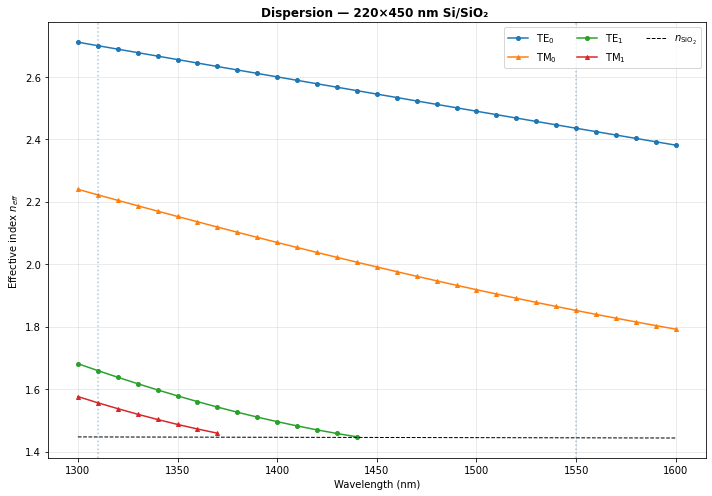

In [8]:
wls_nm = np.linspace(1300, 1600, 31)
te_data = {i: {"wl": [], "n": []} for i in range(4)}
tm_data = {i: {"wl": [], "n": []} for i in range(4)}
neff_guess_TE = None
neff_guess_TM = None

for wl_nm in wls_nm:
    wl = wl_nm * 1e-9
    wl_um = wl * 1e6
    nc = n_Si(wl_um)
    ncl = n_SiO2(wl_um)
    if neff_guess_TE is None:
        neff_guess_TE = 0.85*nc
    if neff_guess_TM is None:
        neff_guess_TM = 0.70*nc

    modes, _, _, _ = solver.solve(
        wl, nmodes=8,
        neff_guess={"TE": neff_guess_TE, "TM": neff_guess_TM},
        nk_extra=16, verbose=False
    )
    te0 = get_mode(modes, "TE", 0)
    tm0 = get_mode(modes, "TM", 0)
    if te0 is not None:
        neff_guess_TE = te0["neff"]
    if tm0 is not None:
        neff_guess_TM = tm0["neff"]

    for m in modes:
        d = te_data if m["pol"] == "TE" else tm_data
        o = m["order"]
        if o < 4:
            d[o]["wl"].append(wl_nm)
            d[o]["n"].append(m["neff"])

fig, ax = plt.subplots(figsize=(10, 7))

for i in range(4):
    if te_data[i]["wl"]:
        ax.plot(te_data[i]["wl"], te_data[i]["n"], "-o", ms=4, lw=1.5, label=f"TE$_{i}$")
    if tm_data[i]["wl"]:
        ax.plot(tm_data[i]["wl"], tm_data[i]["n"], "-^", ms=4, lw=1.5, label=f"TM$_{i}$")

wf = np.linspace(1300, 1600, 200)
ax.plot(wf, [n_SiO2(w/1e3) for w in wf], "k--", lw=1, label=r"$n_{\mathrm{SiO_2}}$")
ax.axvline(1310, ls=":", alpha=0.4)
ax.axvline(1550, ls=":", alpha=0.4)
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel(r"Effective index $n_{eff}$")
ax.set_title("Dispersion — 220×450 nm Si/SiO₂ ", fontweight="bold")
ax.grid(True, alpha=0.3)
ax.legend(ncol=3, fontsize=10, loc="upper right")
plt.tight_layout()
plt.show()


**In last plot: The effective indices of the guided modes decrease monotonically with wavelength as modal confinement weakens. Higher-order modes (TE_1 and TM_1) approach cutoff near the cladding index and disappear from the spectrum, leaving only the fundamental TE_0and TM_0 modes across most of the C-band. This behavior explains why the 220 × 450 nm geometry supports robust single-mode TE operation over standard telecom wavelengths.**

**Finally : Core-confinement versus wavelength**

To quantify how confinement changes across the telecom band, I compute a simple core energy fraction
$
\Gamma_{\mathrm{core}}(\lambda)=\frac{\int_{\mathrm{core}} |E(x,y)|^2\,dA}{\int_{\mathrm{all}} |E(x,y)|^2\,dA},
$
using the reconstructed vector magnitude $ |E|^2 = E_x^2+E_y^2+E_z^2 $. This gives a compact measure of how much modal energy remains inside the silicon core as wavelength increases.


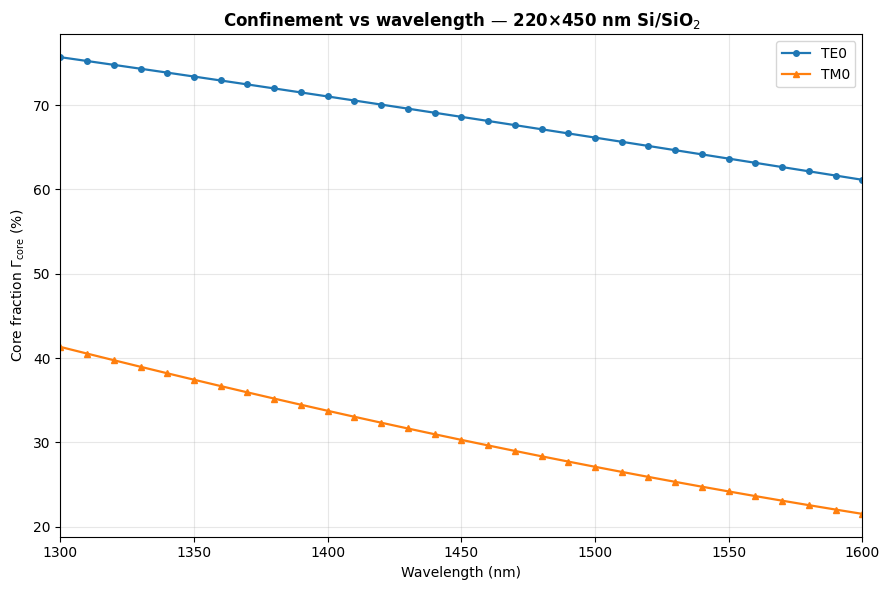

In [13]:
def core_mask_from_solver(solver):
    X, Y = np.meshgrid(solver.x, solver.y, indexing="ij")
    core = (np.abs(X) <= solver.w_core/2) & (np.abs(Y) <= solver.h_core/2)
    return core

def gamma_core(mode, core_mask):
    Ex, Ey, Ez = mode["Ex"], mode["Ey"], mode["Ez"]
    e2 = Ex**2 + Ey**2 + Ez**2
    num = np.sum(e2[core_mask])
    den = np.sum(e2) 
    return num / den

# compute for TE0 and TM0 
wls_nm = np.linspace(1300, 1600, 31)
core_mask = core_mask_from_solver(solver)
g_te0 = []
g_tm0 = []
ne_te0 = []
ne_tm0 = []
neff_guess_TE = None
neff_guess_TM = None

for wl_nm in wls_nm:
    wl = wl_nm * 1e-9
    wl_um = wl * 1e6
    nc = n_Si(wl_um)
    if neff_guess_TE is None:
        neff_guess_TE = 0.85 * nc
    if neff_guess_TM is None:
        neff_guess_TM = 0.70 * nc
    modes, _, _, _ = solver.solve(wl, nmodes=8,neff_guess={"TE": neff_guess_TE, "TM": neff_guess_TM},nk_extra=16,verbose=False)
    te0 = next((m for m in modes if m["pol"]=="TE" and m["order"]==0), None)
    tm0 = next((m for m in modes if m["pol"]=="TM" and m["order"]==0), None)
    if te0 is not None:
        neff_guess_TE = te0["neff"]
        g_te0.append(gamma_core(te0, core_mask))
        ne_te0.append(te0["neff"])
    else:
        g_te0.append(np.nan)
        ne_te0.append(np.nan)
        
    if tm0 is not None:
        neff_guess_TM = tm0["neff"]
        g_tm0.append(gamma_core(tm0, core_mask))
        ne_tm0.append(tm0["neff"])
    else:
        g_tm0.append(np.nan)
        ne_tm0.append(np.nan)
g_te0 = np.array(g_te0)
g_tm0 = np.array(g_tm0)
fig, ax = plt.subplots(figsize=(9, 6), dpi=100)
ax.plot(wls_nm, 100*g_te0, "-o", ms=4, lw=1.6, label="TE0")
ax.plot(wls_nm, 100*g_tm0, "-^", ms=4, lw=1.6, label="TM0")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel(r"Core fraction $\Gamma_{\mathrm{core}}$ (%)")
ax.set_title(r"Confinement vs wavelength — 220×450 nm Si/SiO$_2$", fontweight="bold")
ax.grid(True, alpha=0.3)
ax.set_xlim(1300, 1600)
ax.legend()
plt.tight_layout()
plt.show()


However, main caveat :  am using semi-vectorial, not full-vector. At present, am solving a scalar eigenproblem for Ex (TE-like) and Ey (TM-like) and reconstruct Ez. It does gives the right qualitative picture, but it will bias $n_{eff}$ and the minor components, especially for TM-like modes and near cutoff. Full-vector FDE/FEM mode solvers handle all components and anisotropy directly (e.g., Fallahkhair et al., JLT 2008; Zhu & Brown, OE 2002).

In [18]:
!jupyter nbconvert --to webpdf mode_FDTD.ipynb


[NbConvertApp] Converting notebook mode_FDTD.ipynb to webpdf
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Building PDF
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 409837 bytes to mode_FDTD.pdf


SyntaxError: invalid syntax (4045305463.py, line 1)